<a href="https://colab.research.google.com/github/edvakasas/Tensorflow/blob/main/treniruociu_planuotojas_gemini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏋️ DI treniruočių planuotojas (Gemini API)

**Generatyviuoju dirbtiniu intelektu grįsta adaptyvi sporto treniruočių planavimo informacinė sistema – prototipas**

Vartotojas nurodo tikslą, pasirengimo lygį, turimą įrangą ir laiką. Sistema:
1. **atrenka tinkamus pratimus** iš katalogo (deterministiškai, be LLM);
2. **sugeneruoja treniruočių planą** su Gemini struktūrizuotos išvesties režimu (JSON pagal schemą);
3. **validuoja** atsakymą (schema, pratimų ID, krūvio ir trukmės ribos) ir, jei reikia, **pakartoja užklausą** su klaidų sąrašu (iki 3 kartų);
4. pagal įvestus treniruočių rezultatus (RPE, atlikti pakartojimai) **koreguoja planą** – sukuria naują versiją;
5. **atsako į klausimus** natūralia kalba – DI agentas pats kviečia pratimų paieškos įrankį (function calling).

Prototipas įgyvendina tą pačią architektūrą kaip [projekto diagramos](https://github.com/edvakasas/Tensorflow/tree/main/docs/diagrams): vietoj PostgreSQL naudojami CSV/JSON failai, vietoj REST API – Python funkcijos. Funkcijų pavadinimai atitinka komponentų diagramą (`ExerciseCatalogService`, `PromptBuilder`, `LlmGateway`, `ResponseValidator`, `ProgressAnalyzer`).

![Komponentų diagrama](https://raw.githubusercontent.com/edvakasas/Tensorflow/main/docs/diagrams/plantuml/Components.png)

**Duomenys:** pratimų katalogas (42 pratimai) ir 5 End-to-End (X, y) pavyzdžiai iš [`/data`](https://github.com/edvakasas/Tensorflow/tree/main/data).

**Paruošimas:** Gemini API raktą iš [Google AI Studio](https://aistudio.google.com/apikey) įrašykite į Colab **Secrets** (rakto piktograma kairėje) pavadinimu `GOOGLE_API_KEY` ir įjunkite „Notebook access“.

*[Edvin Gladkich, Nojus Sadaunykas]*

In [ ]:
#@title 🔗 SETUP: priklausomybės, API raktas ir projekto duomenys
!pip install -U -q "google-genai" pydantic

import os
from google.colab import userdata

os.environ["GEMINI_API_KEY"] = userdata.get("GOOGLE_API_KEY")  # raktas iš Colab Secrets, niekada ne kode

# Atsisiunčiame projekto saugyklą: katalogą, (X, y) pavyzdžius ir sistemos promptą
!rm -rf /content/repo && git clone -q https://github.com/edvakasas/Tensorflow.git /content/repo
REPO_DIR = "/content/repo"

from google import genai
from google.genai import types

client = genai.Client(http_options=types.HttpOptions(timeout=120_000))  # ms; kad užstrigusi užklausa nelauktų amžinai
MODEL = "gemini-3.8-flash"
FALLBACK_MODELS = ["gemini-3.7-flash", "gemini-3.6-flash", "gemini-3.5-flash"]  # naudojami, jei pagrindinis modelis perkrautas
# Jei modelis nebepasiekiamas (404), pasirinkite kitą iš šio sąrašo:
print("Prieinami Flash modeliai:", [m.name.removeprefix("models/") for m in client.models.list()
                                    if "flash" in m.name and "generateContent" in (m.supported_actions or [])])

Prieinami Flash modeliai: ['gemini-2.5-flash', 'gemini-2.5-flash-preview-tts', 'gemini-flash-latest', 'gemini-flash-lite-latest', 'gemini-2.5-flash-lite', 'gemini-2.5-flash-image', 'gemini-3-flash-preview', 'gemini-3.1-flash-lite-preview', 'gemini-3.1-flash-lite', 'gemini-3.1-flash-image-preview', 'gemini-3.1-flash-image', 'gemini-3.1-flash-lite-image', 'gemini-3.5-flash', 'gemini-3.5-flash-lite', 'gemini-omni-flash-preview', 'gemini-omni-1.1-flash', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'gemini-3.1-flash-tts-preview', 'gemini-3.8-flash-tts', 'gemini-3.8-flash-lite-tts']


## 1 žingsnis – duomenų įkėlimas
**Pratimų katalogas** atitinka `exercises` ir `exercise_equipment` lenteles iš ER diagramos. `unit` nurodo, ar pratimas matuojamas pakartojimais, ar sekundėmis (pvz. lenta).

**(X, y) poros:** `X` – sistemos įvestis (profilis, esamas planas ir rezultatai arba klausimas), `y` – pavyzdinis teisingas atsakymas ir **priėmimo kriterijai**. LLM kaskart sugeneruoja šiek tiek kitokį planą, todėl automatiškai tikriname kriterijus, o ne tikslų sutapimą su pavyzdžiu.

In [ ]:
#@title 📥 STEP 1: Pratimų katalogas ir (X, y) pavyzdžiai
import json, glob, os
import pandas as pd

catalog = pd.read_csv(f"{REPO_DIR}/data/exercises_catalog.csv")
catalog["equipment"] = catalog["equipment"].str.split(";")
CATALOG = catalog.set_index("id")

EXAMPLES = {}
for x_path in sorted(glob.glob(f"{REPO_DIR}/data/X/*.json")):
    name = os.path.basename(x_path).removesuffix(".json")
    with open(x_path, encoding="utf-8") as f:
        x = json.load(f)
    with open(f"{REPO_DIR}/data/y/{name}.json", encoding="utf-8") as f:
        y = json.load(f)
    EXAMPLES[name] = {"X": x, "y": y}

print(f"Pratimų kataloge: {len(catalog)}, (X, y) porų: {len(EXAMPLES)}\n")
for name, e in EXAMPLES.items():
    print(f"{name}: [{e['X']['scenario']}] {e['X']['description']}")
display(catalog.head(8))

Pratimų kataloge: 42, (X, y) porų: 5

example_01: [PLAN_GENERATION] Pradedančioji, be įrangos, svorio metimas, 3×30 min
example_02: [PLAN_GENERATION] Pažengęs, sporto salė, raumenų masė, 4×60 min
example_03: [PLAN_ADJUSTMENT] Esamas planas + 3 treniruotės su RPE 9–10 ir neatliktais pakartojimais
example_04: [CHAT] Klausimas natūralia kalba apie pratimo pakeitimą
example_05: [PLAN_GENERATION] Nerealus noras: pradedantysis, 7×180 min


,id,name,name_lt,muscle_group,difficulty,equipment,unit,is_active
0,EX01,Push-up,Atsispaudimai,chest,BEGINNER,[none],reps,True
1,EX02,Knee push-up,Atsispaudimai nuo kelių,chest,BEGINNER,[none],reps,True
2,EX03,Diamond push-up,Deimantiniai atsispaudimai,triceps,INTERMEDIATE,[none],reps,True
3,EX04,Bodyweight squat,Pritūpimai be svorio,legs,BEGINNER,[none],reps,True
4,EX05,Reverse lunge,Atgaliniai įtupstai,legs,BEGINNER,[none],reps,True
5,EX06,Glute bridge,Dubens kėlimas,glutes,BEGINNER,[none],reps,True
6,EX07,Plank,Lenta,core,BEGINNER,[none],seconds,True
7,EX08,Side plank,Šoninė lenta,core,INTERMEDIATE,[none],seconds,True


## 2 žingsnis – išvesties schema
Pydantic modeliai atitinka domeno modelio klases `TrainingPlan` → `PlannedSession` → `PlannedExercise`. Ta pati schema perduodama Gemini (`response_schema`), todėl modelis privalo grąžinti būtent tokios struktūros JSON. Schema taip pat išsaugota faile [`schemas/plan_schema.json`](https://github.com/edvakasas/Tensorflow/blob/main/schemas/plan_schema.json).

In [ ]:
#@title 🧱 STEP 2: Plano JSON schema (Pydantic)
from typing import Optional
from pydantic import BaseModel, Field

class PlannedExercise(BaseModel):
    exerciseId: str = Field(description="Pratimo ID iš katalogo, pvz. EX04")
    orderIndex: int
    sets: int
    reps: int = Field(description="Pakartojimai; jei pratimo unit = seconds, trukmė sekundėmis")
    targetWeightKg: Optional[float] = Field(None, description="Tik pratimams su svoriais, kitaip null")
    restSeconds: int

class PlannedSession(BaseModel):
    weekNumber: int
    dayOfWeek: int = Field(description="1 = pirmadienis ... 7 = sekmadienis")
    title: str
    exercises: list[PlannedExercise]

class TrainingPlan(BaseModel):
    title: str
    durationWeeks: int
    notes: str = Field(description="1-3 sakiniai vartotojui lietuviškai")
    changeReason: Optional[str] = Field(None, description="Pildoma tik koreguojant planą")
    sessions: list[PlannedSession]

print(json.dumps(TrainingPlan.model_json_schema(), ensure_ascii=False, indent=1)[:1200], "...")

{
 "$defs": {
  "PlannedExercise": {
   "properties": {
    "exerciseId": {
     "description": "Pratimo ID iš katalogo, pvz. EX04",
     "title": "Exerciseid",
     "type": "string"
    },
    "orderIndex": {
     "title": "Orderindex",
     "type": "integer"
    },
    "sets": {
     "title": "Sets",
     "type": "integer"
    },
    "reps": {
     "description": "Pakartojimai; jei pratimo unit = seconds, trukmė sekundėmis",
     "title": "Reps",
     "type": "integer"
    },
    "targetWeightKg": {
     "anyOf": [
      {
       "type": "number"
      },
      {
       "type": "null"
      }
     ],
     "default": null,
     "description": "Tik pratimams su svoriais, kitaip null",
     "title": "Targetweightkg"
    },
    "restSeconds": {
     "title": "Restseconds",
     "type": "integer"
    }
   },
   "required": [
    "exerciseId",
    "orderIndex",
    "sets",
    "reps",
    "restSeconds"
   ],
   "title": "PlannedExercise",
   "type": "object"
  },
  "PlannedSession": {
   "

## 3 žingsnis – saugumo ribos ir pratimų atranka (be LLM)
Prieš kviečiant LLM sistema **deterministiškai**:
- apriboja nerealius norus (pvz. pradedantysis – ne daugiau kaip 4 treniruotės po 60 min);
- atrenka tik tuos pratimus, kurie tinka vartotojo lygiui ir turimai įrangai (`ExerciseCatalogService.findSuitable`).

Taip modelis net nemato netinkamų pratimų, o validatorius vėliau gali patikrinti jų ID.

In [ ]:
#@title 🛡️ STEP 3: Profilio ribos ir pratimų atranka
LEVELS = ["BEGINNER", "INTERMEDIATE", "ADVANCED"]
LIMITS = {"BEGINNER": (4, 60), "INTERMEDIATE": (5, 90), "ADVANCED": (6, 120)}  # (treniruočių/sav., min)

def normalize_profile(profile):
    """Grąžina (apribotas profilis, pastabų sąrašas)."""
    p, warnings = dict(profile), []
    max_sessions, max_minutes = LIMITS[p["fitnessLevel"]]
    if p["sessionsPerWeek"] > max_sessions:
        warnings.append(f"Treniruočių per savaitę sumažinta nuo {p['sessionsPerWeek']} iki {max_sessions} (lygis {p['fitnessLevel']}).")
        p["sessionsPerWeek"] = max_sessions
    if p["minutesPerSession"] > max_minutes:
        warnings.append(f"Treniruotės trukmė sumažinta nuo {p['minutesPerSession']} iki {max_minutes} min (lygis {p['fitnessLevel']}).")
        p["minutesPerSession"] = max_minutes
    return p, warnings

def select_exercises(profile):
    """ExerciseCatalogService.findSuitable: lygis ir įranga."""
    have = set(profile["equipment"]) | {"none"}
    level = LEVELS.index(profile["fitnessLevel"])
    ok = (catalog["is_active"]
          & catalog["difficulty"].map(LEVELS.index).le(level)
          & catalog["equipment"].map(lambda eq: set(eq) <= have))
    return catalog[ok]

demo_profile, demo_warnings = normalize_profile(EXAMPLES["example_05"]["X"]["profile"])
print("Pavyzdys 5:", demo_warnings)
print(f"Pavyzdžiui 1 tinka {len(select_exercises(EXAMPLES['example_01']['X']['profile']))} pratimai iš {len(catalog)}")

Pavyzdys 5: ['Treniruočių per savaitę sumažinta nuo 7 iki 4 (lygis BEGINNER).', 'Treniruotės trukmė sumažinta nuo 180 iki 60 min (lygis BEGINNER).']
Pavyzdžiui 1 tinka 10 pratimai iš 42


## 4 žingsnis – prompto sudarymas (`PromptBuilder`)
Sistemos instrukcijos (rolė ir taisyklės) saugomos [`prompts/system_prompt.md`](https://github.com/edvakasas/Tensorflow/blob/main/prompts/system_prompt.md). Vartotojo užklausą sudaro profilis, saugumo pastabos ir leidžiamų pratimų sąrašas. Žemiau parodytas pilnas promptas, kuris siunčiamas modeliui.

In [ ]:
#@title ✍️ STEP 4: PromptBuilder
with open(f"{REPO_DIR}/prompts/system_prompt.md", encoding="utf-8") as f:
    SYSTEM_PROMPT = f.read()

def catalog_text(df):
    rows = [f"{r.id} | {r.name} | {r.muscle_group} | {r.difficulty} | {'+'.join(r.equipment)} | {r.unit}" for r in df.itertuples()]
    return "\n".join(rows)

def build_generation_prompt(profile, allowed, warnings):
    notes = "\n".join(warnings) or "nėra"
    return f"""VARTOTOJO PROFILIS:
{json.dumps(profile, ensure_ascii=False, indent=1)}

SAUGUMO PASTABOS (jau pritaikytos profiliui, paaiškink jas lauke notes):
{notes}

LEIDŽIAMI PRATIMAI (id | name | muscle_group | difficulty | equipment | unit):
{catalog_text(allowed)}

UŽDUOTIS: sudaryk 4 savaičių planą (durationWeeks = 4). Pateik {profile['sessionsPerWeek']} pirmos savaitės treniruotes,
kiekviena ne ilgesnė nei {profile['minutesPerSession']} min."""

p1, w1 = normalize_profile(EXAMPLES["example_01"]["X"]["profile"])
print(build_generation_prompt(p1, select_exercises(p1), w1))

VARTOTOJO PROFILIS:
{
 "goal": "WEIGHT_LOSS",
 "fitnessLevel": "BEGINNER",
 "sessionsPerWeek": 3,
 "minutesPerSession": 30,
 "equipment": [],
 "notes": "Sportuoju namuose vakarais, įrangos neturiu."
}

SAUGUMO PASTABOS (jau pritaikytos profiliui, paaiškink jas lauke notes):
nėra

LEIDŽIAMI PRATIMAI (id | name | muscle_group | difficulty | equipment | unit):
EX01 | Push-up | chest | BEGINNER | none | reps
EX02 | Knee push-up | chest | BEGINNER | none | reps
EX04 | Bodyweight squat | legs | BEGINNER | none | reps
EX05 | Reverse lunge | legs | BEGINNER | none | reps
EX06 | Glute bridge | glutes | BEGINNER | none | reps
EX07 | Plank | core | BEGINNER | none | seconds
EX09 | Mountain climbers | cardio | BEGINNER | none | seconds
EX11 | Jumping jacks | cardio | BEGINNER | none | seconds
EX12 | Superman hold | back | BEGINNER | none | seconds
EX41 | Jogging | cardio | BEGINNER | none | seconds

UŽDUOTIS: sudaryk 4 savaičių planą (durationWeeks = 4). Pateik 3 pirmos savaitės treniruotes,
kiekv

## 5 žingsnis – Gemini kvietimas (`LlmGateway`)
Kiekvienas kvietimas įrašomas į `LLM_LOG` (atitinka `llm_requests` lentelę): tikslas, bandymo numeris, trukmė, žetonai, validumas. Planams naudojamas struktūrizuotos išvesties režimas: `response_mime_type="application/json"` ir `response_schema=TrainingPlan`.

In [ ]:
#@title 🤖 STEP 5: LlmGateway – Gemini API kvietimas
import time
import httpx
from google.genai import errors

LLM_LOG = []  # llm_requests

def generate_with_fallback(prompt, config):
    """Laikinos API klaidos (perkrova, limitai): kartojame po pauzės, tada bandome atsarginį modelį."""
    last_error = None
    for model in [MODEL, *FALLBACK_MODELS]:
        for wait in (0, 20):
            time.sleep(wait)
            try:
                return model, client.models.generate_content(model=model, contents=prompt, config=config)
            except (errors.APIError, httpx.TimeoutException) as e:
                if isinstance(e, errors.APIError) and e.code not in (429, 500, 503, 504):
                    raise
                last_error = e
                print(f"   ⏳ {model}: {getattr(e, 'code', 'timeout')}, bandoma dar kartą...")
    raise last_error

def call_gemini(prompt, purpose, schema=None, tools=None, system=None, attempt=1):
    config = {"system_instruction": system or SYSTEM_PROMPT, "temperature": 0.4,
              "thinking_config": types.ThinkingConfig(thinking_level="low")}  # užduočiai nereikia ilgo „mąstymo“
    if schema is not None:
        config.update(response_mime_type="application/json", response_schema=schema)
    if tools:
        config["tools"] = tools
    start = time.time()
    model, response = generate_with_fallback(prompt, types.GenerateContentConfig(**config))
    usage = response.usage_metadata
    LLM_LOG.append({"purpose": purpose, "model": model, "attempt": attempt, "seconds": round(time.time() - start, 1),
                    "tokens": usage.total_token_count if usage else None, "valid": None,
                    "prompt": prompt, "rawResponse": response.text})
    return response

## 6 žingsnis – atsakymo validavimas (`ResponseValidator`)
LLM atsakymu nepasitikime aklai. Prieš „įrašant į DB“ tikrinama:
1. ar JSON atitinka schemą;
2. ar treniruočių skaičius ir savaitės dienos teisingi;
3. ar visi pratimų ID yra tarp **leidžiamų** (katalogas + lygis + įranga);
4. ar serijos, pakartojimai ir poilsis neviršija ribų;
5. ar apskaičiuota treniruotės trukmė neviršija vartotojo laiko.

Klaidos grąžinamos tekstu, kad jas būtų galima perduoti modeliui pakartotiniam bandymui.

In [ ]:
#@title ✅ STEP 6: ResponseValidator
WARMUP_MIN = 5
LOADED_EQUIPMENT = {"barbell", "dumbbells", "cable_machine", "leg_press_machine", "kettlebell", "dip_station"}

def estimate_minutes(session):
    seconds = 0
    for e in session.exercises:
        if e.exerciseId not in CATALOG.index:
            continue
        work = e.reps if CATALOG.loc[e.exerciseId, "unit"] == "seconds" else e.reps * 3
        seconds += e.sets * (work + e.restSeconds)
    return WARMUP_MIN + seconds / 60

def validate_plan(raw_json, profile, allowed):
    """Grąžina (TrainingPlan arba None, klaidų sąrašas)."""
    try:
        plan = TrainingPlan.model_validate_json(raw_json)
    except Exception as e:
        return None, [f"JSON neatitinka schemos: {str(e)[:300]}"]
    errors, allowed_ids = [], set(allowed["id"])
    if len(plan.sessions) != profile["sessionsPerWeek"]:
        errors.append(f"Treniruočių yra {len(plan.sessions)}, turi būti {profile['sessionsPerWeek']}.")
    days = [s.dayOfWeek for s in plan.sessions]
    if len(set(days)) != len(days) or not all(1 <= d <= 7 for d in days):
        errors.append(f"Netinkamos savaitės dienos {days}: turi būti skirtingos, 1–7.")
    for s in plan.sessions:
        if s.weekNumber != 1:
            errors.append(f"'{s.title}': weekNumber turi būti 1.")
        if not s.exercises:
            errors.append(f"'{s.title}': nėra pratimų.")
        for e in s.exercises:
            if e.exerciseId not in allowed_ids:
                errors.append(f"'{s.title}': pratimas {e.exerciseId} neleidžiamas (nėra kataloge arba netinka lygiui ar įrangai).")
                continue
            lo, hi = (10, 1800) if CATALOG.loc[e.exerciseId, "unit"] == "seconds" else (1, 30)
            if not 1 <= e.sets <= 6:
                errors.append(f"'{s.title}' {e.exerciseId}: serijų {e.sets}, leidžiama 1–6.")
            if not lo <= e.reps <= hi:
                errors.append(f"'{s.title}' {e.exerciseId}: reps {e.reps}, leidžiama {lo}–{hi}.")
            if not 0 <= e.restSeconds <= 300:
                errors.append(f"'{s.title}' {e.exerciseId}: poilsis {e.restSeconds} s, leidžiama 0–300.")
        minutes = estimate_minutes(s)
        if minutes > profile["minutesPerSession"]:
            errors.append(f"'{s.title}': trukmė ~{minutes:.0f} min viršija {profile['minutesPerSession']} min.")
    return plan, errors

# Patikra: pavyzdinis y atsakymas turi būti validus, o sugadintas – ne
p, _ = normalize_profile(EXAMPLES["example_01"]["X"]["profile"])
ref = json.dumps(EXAMPLES["example_01"]["y"]["reference"])
print("Pavyzdinis planas:", validate_plan(ref, p, select_exercises(p))[1] or "✅ validus")
broken = ref.replace("EX04", "EX26")  # pritūpimai su štanga – įrangos nėra
print("Sugadintas planas:", validate_plan(broken, p, select_exercises(p))[1])

Pavyzdinis planas: ✅ validus
Sugadintas planas: ["'Viso kūno A': pratimas EX26 neleidžiamas (nėra kataloge arba netinka lygiui ar įrangai)."]


## 7 žingsnis – plano generavimas su pakartotiniais bandymais (`PlanService.generatePlan`)
Atitinka sekų diagramą „Plano generavimas“: jei validacija nepavyksta, klaidos pridedamos prie prompto ir bandoma iš naujo (iki 3 kartų). Nepavykus – `PlanGenerationException` (API grąžintų 502).

In [ ]:
#@title 🔁 STEP 7: PlanService – generavimas ir pakartojimai
MAX_ATTEMPTS = 3

class PlanGenerationException(Exception):
    pass

def run_with_validation(prompt, purpose, profile, allowed):
    for attempt in range(1, MAX_ATTEMPTS + 1):
        response = call_gemini(prompt, purpose, schema=TrainingPlan, attempt=attempt)
        plan, errors = validate_plan(response.text, profile, allowed)
        LLM_LOG[-1]["valid"] = not errors
        print(f"   bandymas {attempt}: " + ("✅ validus" if not errors else "❌ " + " | ".join(errors)))
        if not errors:
            return plan
        prompt += "\n\nANKSTESNIS ATSAKYMAS NEVALIDUS. Ištaisyk šias klaidas:\n- " + "\n- ".join(errors)
    raise PlanGenerationException(f"Nepavyko gauti validaus plano per {MAX_ATTEMPTS} bandymus")

def generate_plan(x):
    profile, warnings = normalize_profile(x["profile"])
    allowed = select_exercises(profile)
    print(f"▶ {x['description']}\n   leidžiamų pratimų: {len(allowed)}; ribos: {warnings or 'nėra'}")
    plan = run_with_validation(build_generation_prompt(profile, allowed, warnings), "PLAN_GENERATION", profile, allowed)
    return plan

def plan_table(plan):
    days = ["", "Pr", "An", "Tr", "Kt", "Pn", "Št", "Sk"]
    rows = []
    for s in sorted(plan.sessions, key=lambda s: s.dayOfWeek):
        for e in s.exercises:
            ex = CATALOG.loc[e.exerciseId]
            amount = f"{e.sets} × {e.reps}" + (" s" if ex.unit == "seconds" else "")
            rows.append({"Diena": days[s.dayOfWeek], "Treniruotė": s.title, "Pratimas": ex.name_lt,
                         "Serijos × kartai": amount, "Svoris, kg": e.targetWeightKg or "–",
                         "Poilsis, s": e.restSeconds, "~min": round(estimate_minutes(s))})
    return pd.DataFrame(rows).set_index(["Diena", "Treniruotė", "~min"])

## 8 žingsnis – End-to-End: planų generavimas (pavyzdžiai 1, 2, 5)
Kiekvienam pavyzdžiui parodoma: įvestis → atrinkti pratimai → bandymai → galutinis planas.

In [ ]:
#@title 🏃 STEP 8: Planų generavimas pavyzdžiams 1, 2 ir 5
RESULTS = {}
for name in ["example_01", "example_02", "example_05"]:
    x = EXAMPLES[name]["X"]
    calls_before = len(LLM_LOG)
    plan = generate_plan(x)
    RESULTS[name] = {"output": plan, "calls": LLM_LOG[calls_before:]}
    print(f"\n📋 {plan.title}\n💬 {plan.notes}")
    display(plan_table(plan))
    print("\n" + "=" * 100 + "\n")

▶ Pradedančioji, be įrangos, svorio metimas, 3×30 min
   leidžiamų pratimų: 10; ribos: nėra
   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 503, bandoma dar kartą...
   bandymas 1: ✅ validus

📋 Svorio metimo programa namuose pradedantiesiems
💬 Šis planas skirtas riebalų deginimui ir raumenų tonuso didinimui naudojant tik savo kūno svorį. Treniruotės paskirstytos su poilsio dienomis tarp jų, kad užtikrintų saugų ir efektyvų atsistatymą.


Pratimas Serijos × kartai  \
Diena Treniruotė              ~min                                             
Pr    Pilno kūno treniruotė A 27       Pritūpimai be svorio           3 × 12   
                              27    Atsispaudimai nuo kelių           3 × 10   
                              27             Dubens kėlimas           3 × 15   
                              27                      Lenta         3 × 30 s   
                              27       Šuoliukai išskečiant         3 × 45 s   
Tr    Pilno kūno treniruotė B 26        Atgaliniai įtupstai           3 × 10   
                              26                 Supermenas         3 × 30 s   
                              26             Dubens kėlimas           3 × 12   
                              26                    Kopikas         3 × 30 s   
                              26       Šuoliukai išskečiant         3 × 45 s   
Pn    Pilno kūno treniruotė C 27       Pritūpimai be svorio           3 × 15   
                              27    Atsispaudimai nuo kelių            3 × 8   
                              27        Atgaliniai įtupstai           3 × 10   
                              27                      Lenta         3 × 35 s   
                              27                    Kopikas         3 × 30 s   

                                   Svoris, kg  Poilsis, s  
Diena Treniruotė              ~min                         
Pr    Pilno kūno treniruotė A 27            –          60  
                              27            –          60  
                              27            –          45  
                              27            –          45  
                              27            –          45  
Tr    Pilno kūno treniruotė B 26            –          60  
                              26            –          45  
                              26            –          45  
                              26            –          45  
                              26            –          45  
Pn    Pilno kūno treniruotė C 27            –          60  
                              27            –          60  
                              27            –          60  
                              27            –          45  
                              27            –          45



▶ Pažengęs, sporto salė, raumenų masė, 4×60 min
   leidžiamų pratimų: 37; ribos: nėra
   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.8-flash: 503, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
   bandymas 1: ✅ validus

📋 A pažengusiems skirtas Viršaus/Ačios treniruočių planas
💬 Programoje pritaikytas viršutinės ir apatinės kūno dalių padalijimas, skirtas maksimaliai raumenų masės hipertrofijai. Krūviai apskaičiuoti pagal jūsų nurodytus 5 pakartojimų darbinius svorius. Laikykitės nurodytų poilsio pauzių bei kontroliuokite judesio tempą.


Pratimas  \
Diena Treniruotė             ~min                                           
Pr    Viršutinė kūno dalis A 46                  Štangos spaudimas gulint   
                             46                 Štangos trauka pasilenkus   
                             46                 Štangos spaudimas stovint   
                             46                            Prisitraukimai   
                             46    Atsilenkimai ant lygiagrečių su svoriu   
An    Apatinė kūno dalis A   39                      Pritūpimai su štanga   
                             39            Rumuniška trauka su hanteliais   
                             39              Kojų spaudimas treniruoklyje   
                             39                      Kelių kėlimas kabant   
Kt    Viršutinė kūno dalis B 39                 Hantelių spaudimas gulint   
                             39              Apatinio bloko trauka sėdint   
                             39                  Hantelių kėlimas į šonus   
                             39                   Tricepso tiesimas bloke   
                             39            Bicepso lenkimai su hanteliais   
Pn    Apatinė kūno dalis B   36                  Klasikinė mirties trauka   
                             36                     Priekiniai pritūpimai   
                             36                     Bulgariški pritūpimai   
                             36                              Šoninė lenta   

                                  Serijos × kartai Svoris, kg  Poilsis, s  
Diena Treniruotė             ~min                                          
Pr    Viršutinė kūno dalis A 46              4 × 6       85.0         180  
                             46              4 × 6       75.0         120  
                             46              3 × 8       50.0         120  
                             46              3 × 8          –          90  
                             46             3 × 10       10.0          90  
An    Apatinė kūno dalis A   39              4 × 6      110.0         180  
                             39              4 × 8       40.0         120  
                             39             3 × 10      150.0          90  
                             39             3 × 12          –          60  
Kt    Viršutinė kūno dalis B 39              4 × 8       36.0         120  
                             39             4 × 10       70.0          90  
                             39             4 × 12       12.0          60  
                             39             3 × 12       30.0          60  
                             39             3 × 12       14.0          60  
Pn    Apatinė kūno dalis B   36              4 × 5      140.0         180  
                             36              3 × 8       80.0         120  
                             36             3 × 10          –          90  
                             36           3 × 45 s          –          60



▶ Nerealus noras: pradedantysis, 7×180 min
   leidžiamų pratimų: 15; ribos: ['Treniruočių per savaitę sumažinta nuo 7 iki 4 (lygis BEGINNER).', 'Treniruotės trukmė sumažinta nuo 180 iki 60 min (lygis BEGINNER).']
   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.6-flash: 503, bandoma dar kartą...
   ⏳ gemini-3.6-flash: 503, bandoma dar kartą...
   ⏳ gemini-3.5-flash: 503, bandoma dar kartą...
   bandymas 1: ✅ validus

📋 Pradedančiojo svorio metimo planas
💬 Siekiant išvengti perdegimo ir traumų, treniruočių dažnis ir trukmė buvo sumažinti iki saugaus 4 kartų per savaitę po 60 minučių lygio. Šis planas padės saugiai deginti riebalus ir stiprinti raumenis. Progresiją užtikrinsite palaipsniui didindami pakartojimų skaičių ar hantelių svorį.


Pratimas  \
Diena Treniruotė                   ~min                                   
Pr    Viso kūno treniruotė A       28              Pritūpimai be svorio   
                                   28           Atsispaudimai nuo kelių   
                                   28    Hantelių spaudimas virš galvos   
                                   28                             Lenta   
                                   28              Šuoliukai išskečiant   
Tr    Kardio ir jėga               32                 Taurės pritūpimai   
                                   32    Bicepso lenkimai su hanteliais   
                                   32     Tricepso tiesimas virš galvos   
                                   32                           Kopikas   
                                   32               Lėtas bėgimas lauke   
Pn    Viso kūno treniruotė B       29               Atgaliniai įtupstai   
                                   29                    Dubens kėlimas   
                                   29          Hantelių kėlimas į šonus   
                                   29                        Supermenas   
                                   29              Šuoliukai išskečiant   
Št    Kardio ir šerdies treniruotė 34               Lėtas bėgimas lauke   
                                   34                             Lenta   
                                   34                           Kopikas   
                                   34                    Dubens kėlimas   

                                        Serijos × kartai Svoris, kg  \
Diena Treniruotė                   ~min                               
Pr    Viso kūno treniruotė A       28             3 × 15          –   
                                   28             3 × 10          –   
                                   28             3 × 12        4.0   
                                   28           3 × 30 s          –   
                                   28           3 × 45 s          –   
Tr    Kardio ir jėga               32             3 × 12        6.0   
                                   32             3 × 12        4.0   
                                   32             3 × 12        4.0   
                                   32           3 × 30 s          –   
                                   32          3 × 120 s          –   
Pn    Viso kūno treniruotė B       29             3 × 12          –   
                                   29             3 × 15          –   
                                   29             3 × 12        3.0   
                                   29           3 × 30 s          –   
                                   29           3 × 60 s          –   
Št    Kardio ir šerdies treniruotė 34          4 × 180 s          –   
                                   34           3 × 40 s          –   
                                   34           3 × 40 s          –   
                                   34             3 × 15          –   

                                         Poilsis, s  
Diena Treniruotė                   ~min              
Pr    Viso kūno treniruotė A       28            60  
                                   28            60  
                                   28            60  
                                   28            45  
                                   28            45  
Tr    Kardio ir jėga               32            60  
                                   32            60  
                                   32            60  
                                   32            45  
                                   32            60  
Pn    Viso kūno treniruotė B       29            60  
                                   29            60  
                                   29            60  
                                   29            45  
                                   29            45  
Št    Kardio ir šerdies treniruotė 34            60  
                       

## 9 žingsnis – plano koregavimas pagal rezultatus (pavyzdys 3)
Atitinka sekų diagramą „Plano koregavimas“. `ProgressAnalyzer` **be LLM** palygina planuotus ir atliktus pakartojimus bei RPE tendenciją. LLM kviečiamas tik tada, kai korekcija reikalinga, ir sukuria naują plano versiją su `changeReason`.

In [ ]:
#@title 📈 STEP 9a: ProgressAnalyzer (deterministinė analizė)
def analyze_progress(current_plan, logs):
    planned = {(s.dayOfWeek, e.exerciseId): e for s in current_plan.sessions for e in s.exercises}
    rows = []
    for log in logs:
        for r in log["results"]:
            p = planned[(log["dayOfWeek"], r["exerciseId"])]
            rows.append({"date": log["performedAt"], "exerciseId": r["exerciseId"], "rpe": log["rpe"],
                         "completion": r["setsDone"] * r["repsDone"] / (p.sets * p.reps)})
    df = pd.DataFrame(rows)
    avg_rpe = sum(l["rpe"] for l in logs[-3:]) / len(logs[-3:])
    by_ex = df.groupby("exerciseId")["completion"].mean()
    struggling = by_ex[by_ex < 0.85]
    reasons = []
    if avg_rpe >= 9:
        reasons.append(f"Vidutinis RPE paskutinėse treniruotėse {avg_rpe:.1f} (≥ 9) – krūvis per didelis.")
    for ex_id, c in struggling.items():
        reasons.append(f"{ex_id} ({CATALOG.loc[ex_id, 'name_lt']}): atlikta tik {c:.0%} planuotų pakartojimų.")
    if avg_rpe <= 6 and (by_ex >= 1).all():
        reasons.append(f"Vidutinis RPE {avg_rpe:.1f} ir visi pakartojimai atlikti – krūvį galima didinti.")
    return {"needsAdjustment": bool(reasons), "reasons": reasons, "avgRpe": avg_rpe}, df

x3 = EXAMPLES["example_03"]["X"]
current_plan = TrainingPlan.model_validate(x3["currentPlan"])
analysis, progress_df = analyze_progress(current_plan, x3["recentLogs"])
print("Reikia koreguoti:", analysis["needsAdjustment"])
for r in analysis["reasons"]:
    print(" •", r)

Reikia koreguoti: True
 • Vidutinis RPE paskutinėse treniruotėse 9.3 (≥ 9) – krūvis per didelis.
 • EX18 (Hantelių spaudimas gulint): atlikta tik 72% planuotų pakartojimų.
 • EX20 (Taurės pritūpimai): atlikta tik 70% planuotų pakartojimų.


In [ ]:
#@title 🔧 STEP 9b: PlanService.adjustPlan – nauja plano versija
def build_adjustment_prompt(x, current, analysis, allowed, profile):
    reasons = "\n".join("- " + r for r in analysis["reasons"])
    return f"""ESAMAS PLANAS (versija {x['currentVersion']}):
{current.model_dump_json(indent=1)}

TRENIRUOČIŲ REZULTATAI:
{json.dumps(x['recentLogs'], ensure_ascii=False)}

ANALIZĖS IŠVADOS (ProgressAnalyzer):
{reasons}

LEIDŽIAMI PRATIMAI (id | name | muscle_group | difficulty | equipment | unit):
{catalog_text(allowed)}

UŽDUOTIS: sukurk naują plano versiją. Išlaikyk {profile['sessionsPerWeek']} treniruotes, kiekviena ne ilgesnė nei
{profile['minutesPerSession']} min. Keisk tik tai, ką pagrindžia analizė. Lauke changeReason paaiškink pakeitimus."""

def adjust_plan(x):
    profile, _ = normalize_profile(x["profile"])
    allowed = select_exercises(profile)
    current = TrainingPlan.model_validate(x["currentPlan"])
    analysis, _ = analyze_progress(current, x["recentLogs"])
    if not analysis["needsAdjustment"]:
        print("Korekcija nereikalinga – planas lieka nepakeistas.")
        return current
    print(f"▶ {x['description']}")
    return run_with_validation(build_adjustment_prompt(x, current, analysis, allowed, profile),
                               "PLAN_ADJUSTMENT", profile, allowed)

calls_before = len(LLM_LOG)
new_plan = adjust_plan(x3)
RESULTS["example_03"] = {"output": new_plan, "calls": LLM_LOG[calls_before:]}
print(f"\n🔄 Versija {x3['currentVersion']} → {x3['currentVersion'] + 1}\n📝 {new_plan.changeReason}")
display(plan_table(new_plan))

▶ Esamas planas + 3 treniruotės su RPE 9–10 ir neatliktais pakartojimais
   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
   bandymas 1: ✅ validus

🔄 Versija 1 → 2
📝 Sumažintas EX18 svoris (nuo 26 kg/24 kg iki 22 kg) ir EX20 svoris (nuo 28 kg iki 22 kg/24 kg), taip pat šiek tiek sumažinti pakartojimai, kadangi vartotojo vidutinis RPE siekė 9.3 ir nebuvo atliekami planuoti pakartojimai.


Pratimas  \
Diena Treniruotė           ~min                                        
Pr    Viršutinė kūno dalis 33              Hantelių spaudimas gulint   
                           33             Hantelio trauka pasilenkus   
                           33                         Prisitraukimai   
                           33         Hantelių spaudimas virš galvos   
Tr    Kojos ir korpusas    31                      Taurės pritūpimai   
                           31         Rumuniška trauka su hanteliais   
                           31                  Bulgariški pritūpimai   
                           31                                  Lenta   
Pn    Viso kūno            26              Hantelių spaudimas gulint   
                           26                      Taurės pritūpimai   
                           26    Prisitraukimai atvirkštiniu suėmimu   
                           26         Bicepso lenkimai su hanteliais   

                                Serijos × kartai Svoris, kg  Poilsis, s  
Diena Treniruotė           ~min                                          
Pr    Viršutinė kūno dalis 33              4 × 8       22.0          90  
                           33             4 × 10       26.0          90  
                           33              3 × 7          –         120  
                           33             3 × 10       18.0          75  
Tr    Kojos ir korpusas    31             4 × 10       24.0          90  
                           31             4 × 10       26.0          90  
                           31             3 × 10          –          75  
                           31           3 × 45 s          –          45  
Pn    Viso kūno            26             3 × 10       22.0          75  
                           26             3 × 10       22.0          75  
                           26              3 × 8          –          90  
                           26             3 × 12       12.0          60

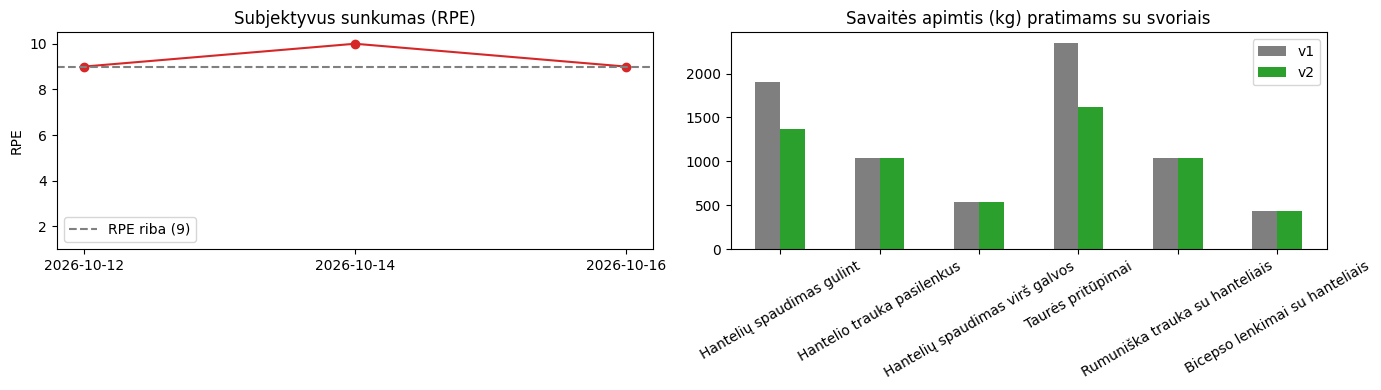

In [ ]:
#@title 📊 STEP 9c: Vizualizacija – RPE ir krūvis prieš / po koregavimo
import matplotlib.pyplot as plt

def load_by_exercise(plan):
    """Apimtis = serijos × kartai × svoris (kūno svorio pratimams – be svorio)."""
    out = {}
    for s in plan.sessions:
        for e in s.exercises:
            out[e.exerciseId] = out.get(e.exerciseId, 0) + e.sets * e.reps * (e.targetWeightKg or 1)
    return pd.Series(out)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
rpe = pd.DataFrame(x3["recentLogs"])[["performedAt", "rpe"]]
ax1.plot(rpe["performedAt"], rpe["rpe"], marker="o", color="tab:red")
ax1.axhline(9, ls="--", color="grey", label="RPE riba (9)")
ax1.set(title="Subjektyvus sunkumas (RPE)", ylim=(1, 10.5), ylabel="RPE")
ax1.legend()

weighted = [e for e in load_by_exercise(current_plan).index if CATALOG.loc[e, "equipment"][0] in LOADED_EQUIPMENT]
compare = pd.DataFrame({"v1": load_by_exercise(current_plan), "v2": load_by_exercise(new_plan)}).fillna(0).loc[weighted]
compare.index = [CATALOG.loc[i, "name_lt"] for i in compare.index]
compare.plot.bar(ax=ax2, color=["tab:grey", "tab:green"], title="Savaitės apimtis (kg) pratimams su svoriais")
ax2.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

## 10 žingsnis – DI agentas: klausimai natūralia kalba (pavyzdys 4)
Čia modelis veikia kaip **agentas**: jam pateikiamas įrankis `search_exercises`, o modelis pats nusprendžia, kada ir su kokiais argumentais jį kviesti (Gemini *function calling*). Įrankis grąžina tik vartotojo lygiui ir įrangai tinkamus pratimus, todėl agentas negali pasiūlyti, pvz., prisitraukimų žmogui be skersinio. Žemiau matyti visa agento eiga: įrankio kvietimai ir galutinis atsakymas.

In [ ]:
#@title 🧭 STEP 10: Agentas su pratimų paieškos įrankiu
import re

CHAT_SYSTEM = ("Esi asmeninis treneris treniruočių planavimo sistemoje. Atsakyk lietuviškai, 3–6 sakiniais. "
               "Pratimus siūlyk TIK iš įrankio search_exercises rezultatų ir prie kiekvieno nurodyk ID "
               "laužtiniuose skliaustuose, pvz. [EX19]. Pratimų nesugalvok.")
TOOL_TRACE = []

def make_search_tool(profile):
    allowed = select_exercises(profile)

    def search_exercises(muscle_group: str) -> list[dict]:
        """Ieško pratimų kataloge pagal raumenų grupę. Grąžina tik vartotojo lygiui ir įrangai tinkamus pratimus.

        Args:
            muscle_group: viena iš chest, back, legs, glutes, hamstrings, shoulders, biceps, triceps, core, cardio
        """
        hits = allowed[allowed["muscle_group"] == muscle_group]
        result = [{"id": r.id, "name": r.name, "name_lt": r.name_lt, "equipment": "+".join(r.equipment)} for r in hits.itertuples()]
        TOOL_TRACE.append({"tool": "search_exercises", "muscle_group": muscle_group, "found": [r["id"] for r in result]})
        return result

    return search_exercises

def answer_question(x):
    profile, _ = normalize_profile(x["profile"])
    TOOL_TRACE.clear()
    prompt = f"VARTOTOJO PROFILIS:\n{json.dumps(profile, ensure_ascii=False)}\n\nKLAUSIMAS: {x['question']}"
    response = call_gemini(prompt, "CHAT", tools=[make_search_tool(profile)], system=CHAT_SYSTEM)
    return response.text

x4 = EXAMPLES["example_04"]["X"]
calls_before = len(LLM_LOG)
answer = answer_question(x4)
RESULTS["example_04"] = {"output": answer, "calls": LLM_LOG[calls_before:]}

print(f"❓ {x4['question']}\n")
for step, t in enumerate(TOOL_TRACE, 1):
    print(f"🔧 {step}. agentas kvietė {t['tool']}(muscle_group='{t['muscle_group']}') → {t['found']}")
print(f"\n💬 {answer}")

   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.8-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
   ⏳ gemini-3.7-flash: 429, bandoma dar kartą...
❓ Kuo pakeisti prisitraukimus, jei neturiu skersinio?

🔧 1. agentas kvietė search_exercises(muscle_group='back') → ['EX12', 'EX19', 'EX37']

💬 Prisitraukimus puikiai pakeis pratimai, nukreipti į nugaros raumenų stiprinimą, kuriems galite panaudoti turimus hantelius, suolėlį ir pasipriešinimo gumą. Puikus pasirinkimas yra hantelio trauka pasilenkus [EX19], leidžianti efektyviai apkrauti nugaros plačiuosius raumenis naudojant suolėlį. Taip pat galite atlikti trauką su guma [EX37], kuri suteikia tolygią raumenų įtampą viso judesio metu. Papildomai nugaros apatinei daliai ir laikysenai stiprinti tinka pratimų kompleksas „Supermenas“ [EX12], kuriam nereikia jokios papildomos įrangos.


## 11 žingsnis – vizualizacija: krūvio pasiskirstymas pagal raumenų grupes
Kiek serijų per savaitę tenka kiekvienai raumenų grupei kiekviename sugeneruotame plane. Tai greitas būdas pamatyti, ar planas subalansuotas ir atitinka tikslą (pvz. svorio metimui daugiau kardio).

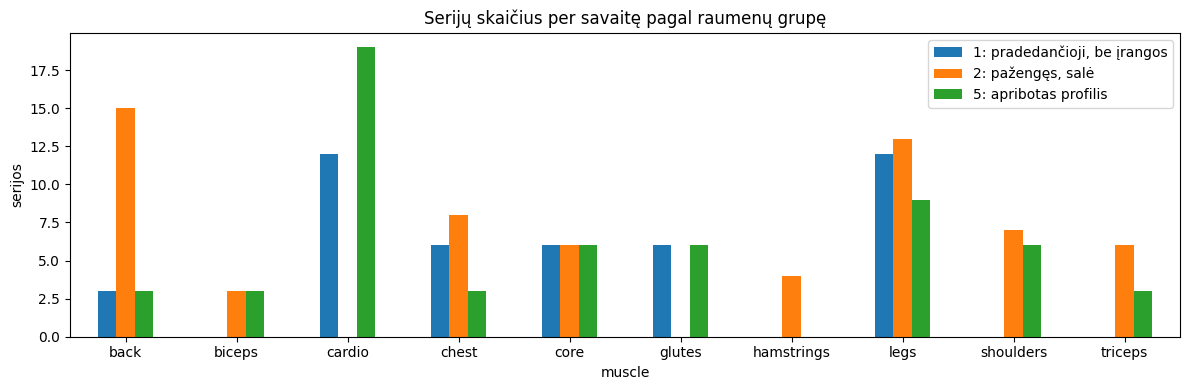

In [ ]:
#@title 📊 STEP 11: Serijos pagal raumenų grupes
def sets_by_muscle(plan):
    rows = [(CATALOG.loc[e.exerciseId, "muscle_group"], e.sets) for s in plan.sessions for e in s.exercises]
    return pd.DataFrame(rows, columns=["muscle", "sets"]).groupby("muscle")["sets"].sum()

labels = {"example_01": "1: pradedančioji, be įrangos", "example_02": "2: pažengęs, salė", "example_05": "5: apribotas profilis"}
volume = pd.DataFrame({labels[k]: sets_by_muscle(RESULTS[k]["output"]) for k in labels}).fillna(0)
volume.plot.bar(figsize=(12, 4), title="Serijų skaičius per savaitę pagal raumenų grupę", ylabel="serijos")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 12 žingsnis – vertinimas pagal (X, y) poras
Kiekvienam pavyzdžiui tikrinami `y` faile aprašyti priėmimo kriterijai. Tie patys kriterijai pritaikomi ir pavyzdiniam atsakymui `y.reference` – jis visada turi gauti 100 %, kitaip klaida yra pačiuose duomenyse.

In [ ]:
#@title 🧪 STEP 12a: Priėmimo kriterijų tikrinimas
def exercises_of(plan):
    return [e for s in plan.sessions for e in s.exercises]

def cited_ids(text):
    return set(re.findall(r"EX\d{2}", text))

def total_load(plan, ex_id):
    return sum(e.sets * e.reps * (e.targetWeightKg or 1) for e in exercises_of(plan) if e.exerciseId == ex_id)

CHECKS = {
    "sessions_per_week": lambda out, want, x: len(out.sessions) == want,
    "max_session_minutes": lambda out, want, x: max(estimate_minutes(s) for s in out.sessions) <= want,
    "allowed_equipment": lambda out, want, x: all(set(CATALOG.loc[e.exerciseId, "equipment"]) <= set(want) | {"none"} for e in exercises_of(out)),
    "max_difficulty": lambda out, want, x: all(LEVELS.index(CATALOG.loc[e.exerciseId, "difficulty"]) <= LEVELS.index(want) for e in exercises_of(out)),
    "notes_present": lambda out, want, x: len(out.notes.strip()) >= 20,
    "change_reason_present": lambda out, want, x: bool(out.changeReason and out.changeReason.strip()),
    "weights_for_loaded": lambda out, want, x: all((e.targetWeightKg or 0) > 0 for e in exercises_of(out) if set(CATALOG.loc[e.exerciseId, "equipment"]) & LOADED_EQUIPMENT),
    "reduced_load_for": lambda out, want, x: all(total_load(out, i) < total_load(TrainingPlan.model_validate(x["currentPlan"]), i) for i in want),
    "cited_min": lambda out, want, x: len(cited_ids(out)) >= want,
    "cited_excluded": lambda out, want, x: not cited_ids(out) & set(want),
    "cited_allowed_equipment": lambda out, want, x: all(i in CATALOG.index and set(CATALOG.loc[i, "equipment"]) <= set(want) | {"none"} for i in cited_ids(out)),
}

def check_criteria(output, example):
    x, criteria = example["X"], example["y"]["criteria"]
    if not isinstance(output, str):
        output = TrainingPlan.model_validate(output) if isinstance(output, dict) else output
    return {k: bool(CHECKS[k](output, want, x)) for k, want in criteria.items()}

# Pavyzdiniai y atsakymai turi atitikti visus savo kriterijus
for name, e in EXAMPLES.items():
    res = check_criteria(e["y"]["reference"], e)
    assert all(res.values()), f"{name}: y.reference neatitinka kriterijų {res}"
print("✅ Visi y.reference atsakymai atitinka savo kriterijus")

✅ Visi y.reference atsakymai atitinka savo kriterijus


In [ ]:
#@title 🧾 STEP 12b: Rezultatų suvestinė
summary = []
for name, e in EXAMPLES.items():
    r = RESULTS[name]
    checks = check_criteria(r["output"], e)
    calls = r["calls"]
    summary.append({
        "Pavyzdys": name, "Scenarijus": e["X"]["scenario"],
        "LLM kvietimai": len(calls),
        "Validus iš 1 karto": "–" if calls[0]["valid"] is None else ("taip" if calls[0]["valid"] else "ne"),
        "Kriterijai": f"{sum(checks.values())}/{len(checks)}",
        "Neįvykdyti": ", ".join(k for k, ok in checks.items() if not ok) or "–",
        "Laikas, s": sum(c["seconds"] for c in calls),
        "Žetonai": sum(c["tokens"] or 0 for c in calls),
    })
summary_df = pd.DataFrame(summary).set_index("Pavyzdys")
display(summary_df)

passed = sum(int(s["Kriterijai"].split("/")[0]) for s in summary)
total = sum(int(s["Kriterijai"].split("/")[1]) for s in summary)
print(f"Priėmimo kriterijų įvykdyta: {passed}/{total} ({passed / total:.0%})")

print("\nLLM užklausų žurnalas (llm_requests):")
display(pd.DataFrame(LLM_LOG)[["purpose", "model", "attempt", "valid", "seconds", "tokens"]])

,Scenarijus,LLM kvietimai,Validus iš 1 karto,Kriterijai,Neįvykdyti,"Laikas, s",Žetonai
Pavyzdys,,,,,,,
example_01,PLAN_GENERATION,1,taip,5/5,–,48.6,1563
example_02,PLAN_GENERATION,1,taip,5/5,–,47.6,3010
example_03,PLAN_ADJUSTMENT,1,taip,5/5,–,46.5,3873
example_04,CHAT,1,–,3/3,–,44.5,795
example_05,PLAN_GENERATION,1,taip,5/5,–,97.1,1912


Priėmimo kriterijų įvykdyta: 23/23 (100%)

LLM užklausų žurnalas (llm_requests):


,purpose,model,attempt,valid,seconds,tokens
0,PLAN_GENERATION,gemini-3.6-flash,1,True,48.6,1563
1,PLAN_GENERATION,gemini-3.6-flash,1,True,47.6,3010
2,PLAN_GENERATION,gemini-3.5-flash,1,True,97.1,1912
3,PLAN_ADJUSTMENT,gemini-3.6-flash,1,True,46.5,3873
4,CHAT,gemini-3.6-flash,1,None,44.5,795


## Išvados ir apribojimai
**Kas veikia:**
- Visa grandinė nuo vartotojo profilio iki validuoto plano: deterministinė atranka → LLM su JSON schema → validavimas → pakartojimas su klaidomis.
- LLM negali „išgalvoti“ pratimų: jis mato tik leidžiamus pratimus, o validatorius tikrina kiekvieną ID.
- Plano koregavimo poreikį nustato deterministinis analizatorius, todėl LLM kviečiamas tik prireikus (pigiau ir lengviau paaiškinti).
- Agentas klausimams pats kviečia paieškos įrankį, o jo eiga matoma.

**Apribojimai:**
- Generuojama tik pirmoji savaitė; kitos savaitės kartoja struktūrą su progresija (pilnoje sistemoje progresiją taikytų `PlanService`).
- Treniruotės trukmė skaičiuojama apytiksliai (3 s vienam pakartojimui).
- Vietoj PostgreSQL – failai atmintyje; vartotojų, autentifikacijos ir versijų saugojimo DB prototipe nėra.
- Rezultatai priklauso nuo modelio versijos ir `temperature`; vertinimas pagal 5 pavyzdžius yra demonstracinis, ne statistinis.